<a href="https://colab.research.google.com/github/cristiancamiloosoriohernandez/Taller-5---Reduccion-de-dimensionalidad-y-clustering-spotify-/blob/main/Taller_5_Reducci%C3%B3n_de_dimensiones_y_clustering_spotify.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CONEXION API

In [ ]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

file_path = "spotifydataset.csv"

datos = kagglehub.dataset_load(KaggleDatasetAdapter.PANDAS,"glowstudygram/spotify-songs-and-artists-dataset", file_path)

datos.head()

100%|██████████| 236k/236k [00:00<00:00, 871kB/s]


,Unnamed: 0,artist_name,genres,followers,artist_popularity,artist_url,track_name,album_name,release_date,duration_ms,...,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,0,Ariana Grande,pop,98934105,89,https://open.spotify.com/artist/66CXWjxzNUsdJx...,we can't be friends (wait for your love),eternal sunshine,2024-03-08,228639,...,0.646,5,-8.334,1,0.0427,0.0615,0.000030,0.0740,0.295,115.842
1,1,Ariana Grande,pop,98934105,85,https://open.spotify.com/artist/66CXWjxzNUsdJx...,the boy is mine,eternal sunshine,2024-03-08,173639,...,0.630,7,-5.854,0,0.0434,0.1570,0.000000,0.0732,0.447,97.998
2,2,Ariana Grande,pop,98934105,83,https://open.spotify.com/artist/66CXWjxzNUsdJx...,intro (end of the world),eternal sunshine,2024-03-08,92400,...,0.362,10,-9.480,1,0.0416,0.6700,0.000000,0.1760,0.385,84.726
3,3,Ariana Grande,pop,98934105,80,https://open.spotify.com/artist/66CXWjxzNUsdJx...,Save Your Tears (Remix) (with Ariana Grande) -...,After Hours (Deluxe),2020-03-20,191013,...,0.825,0,-4.645,1,0.0325,0.0215,0.000024,0.0936,0.593,118.091
4,4,Ariana Grande,pop,98934105,79,https://open.spotify.com/artist/66CXWjxzNUsdJx...,"yes, and?",eternal sunshine,2024-03-08,214994,...,0.775,1,-6.614,1,0.0548,0.1900,0.000065,0.1130,0.787,118.998


# INSPECCIÓN

# Preparación del entorno de trabajo

In [ ]:
# Importar librerias
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans

In [ ]:
# Crear copia del original para trabajar
tabla = datos.copy()

# Limpieza y transformación de datos

In [ ]:
tabla.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 23 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         1000 non-null   int64  
 1   artist_name        1000 non-null   object 
 2   genres             837 non-null    object 
 3   followers          1000 non-null   int64  
 4   artist_popularity  1000 non-null   int64  
 5   artist_url         1000 non-null   object 
 6   track_name         1000 non-null   object 
 7   album_name         1000 non-null   object 
 8   release_date       1000 non-null   object 
 9   duration_ms        1000 non-null   int64  
 10  explicit           1000 non-null   bool   
 11  track_popularity   1000 non-null   int64  
 12  danceability       1000 non-null   float64
 13  energy             1000 non-null   float64
 14  key                1000 non-null   int64  
 15  loudness           1000 non-null   float64
 16  mode               1000 n

In [ ]:
# Identificar columnas de la tabla
tabla.columns

Index(['Unnamed: 0', 'artist_name', 'genres', 'followers', 'artist_popularity',
       'artist_url', 'track_name', 'album_name', 'release_date', 'duration_ms',
       'explicit', 'track_popularity', 'danceability', 'energy', 'key',
       'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness',
       'liveness', 'valence', 'tempo'],
      dtype='object')

In [ ]:
# selección de datos

df = tabla[['danceability', 'energy', 'key', 'loudness', 'mode',
       'speechiness', 'acousticness', 'instrumentalness', 'liveness',
       'valence', 'tempo']]
df.head()

,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,0.645,0.646,5,-8.334,1,0.0427,0.0615,0.000030,0.0740,0.295,115.842
1,0.795,0.630,7,-5.854,0,0.0434,0.1570,0.000000,0.0732,0.447,97.998
2,0.506,0.362,10,-9.480,1,0.0416,0.6700,0.000000,0.1760,0.385,84.726
3,0.650,0.825,0,-4.645,1,0.0325,0.0215,0.000024,0.0936,0.593,118.091
4,0.787,0.775,1,-6.614,1,0.0548,0.1900,0.000065,0.1130,0.787,118.998


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   danceability      1000 non-null   float64
 1   energy            1000 non-null   float64
 2   key               1000 non-null   int64  
 3   loudness          1000 non-null   float64
 4   mode              1000 non-null   int64  
 5   speechiness       1000 non-null   float64
 6   acousticness      1000 non-null   float64
 7   instrumentalness  1000 non-null   float64
 8   liveness          1000 non-null   float64
 9   valence           1000 non-null   float64
 10  tempo             1000 non-null   float64
dtypes: float64(9), int64(2)
memory usage: 86.1 KB


# REDUCCIÓN DE DIMENSIONALIDAD

### Entender los datos

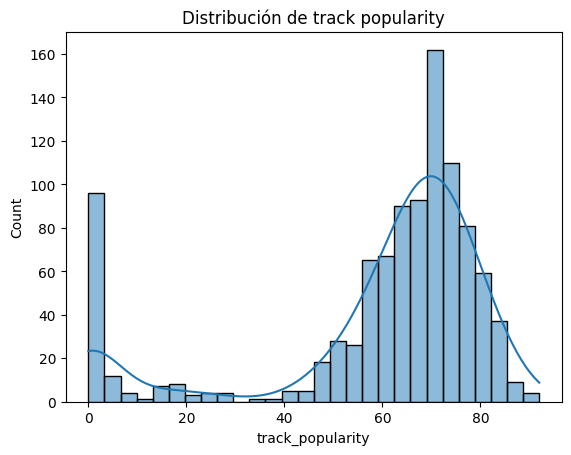

In [ ]:
sns.histplot(tabla, x='track_popularity', kde=True)
plt.title('Distribución de track popularity')
plt.show()

<Axes: xlabel='track_popularity'>

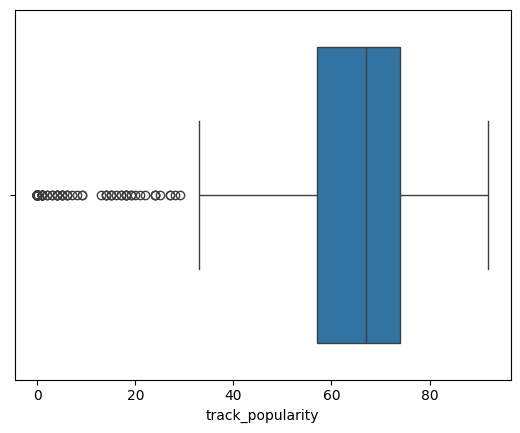

In [ ]:
sns.boxplot(x=tabla['track_popularity'])

In [ ]:
tabla["track_popularity"].unique()

array([89, 85, 83, 80, 79, 82, 78, 70, 84, 74, 73, 72, 81, 77, 76, 92, 87,
       86, 91, 69, 75, 66, 65, 64, 63, 62, 71, 67, 61, 60, 68, 54, 51, 50,
       46, 59, 58, 56, 24, 55, 45, 57, 53, 52, 49, 48, 47, 43, 42, 40, 39,
       41, 28, 27, 21, 18, 16, 15, 14, 20,  2,  1,  0, 17,  9,  8,  5,  4,
        3,  6,  7, 33, 25, 22, 19, 13, 29])

In [ ]:
tabla['track_popularity'].describe()

,track_popularity
count,1000.000000
mean,59.429000
std,23.884963
min,0.000000
25%,57.000000
50%,67.000000
75%,74.000000
max,92.000000


### despues de visualizar los datos para agrupar las canciones más poplares, considero que se puede hacer en 4 grupos:

1.populares
2.buenas
3.conocidas
4.rechazadas

### Escalamiento de datos

In [ ]:
StandardScaler = StandardScaler()
data_scaled = StandardScaler.fit_transform(df)

In [ ]:
data_scaled = pd.DataFrame(data_scaled, columns=df.columns)
data_scaled.head()

,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,0.200823,-0.070192,-0.067277,-0.262122,0.794557,-0.538762,-0.707668,-0.331336,-0.789715,-0.952150,-0.224734
1,1.098154,-0.147313,0.486445,0.291770,-1.258562,-0.531018,-0.376933,-0.331471,-0.795218,-0.299172,-0.861119
2,-0.630704,-1.439104,1.317029,-0.518074,0.794557,-0.550930,1.399684,-0.331471,-0.088114,-0.565518,-1.334449
3,0.230734,0.792609,-1.451583,0.561793,0.794557,-0.651599,-0.846195,-0.331363,-0.654898,0.328030,-0.144526
4,1.050296,0.551603,-1.174722,0.122029,0.794557,-0.404905,-0.262648,-0.331181,-0.521456,1.161436,-0.112179


### t-sne

In [ ]:
x = data_scaled.values

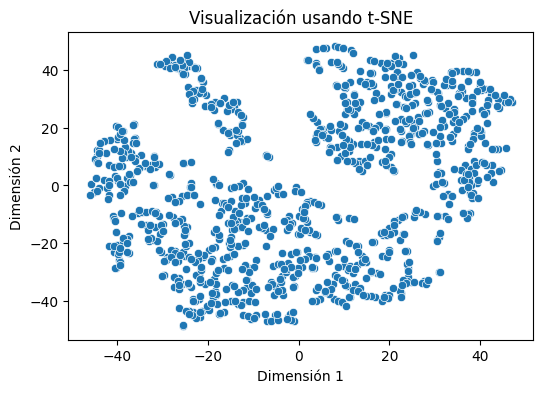

In [ ]:
tsne = TSNE(n_components=2, perplexity=15)
X_tsne = tsne.fit_transform(x)

plt.figure(figsize=(6,4))
sns.scatterplot(x=X_tsne[:,0], y=X_tsne[:,1])
plt.title('Visualización usando t-SNE')
plt.xlabel('Dimensión 1')
plt.ylabel('Dimensión 2')
plt.show() # Veo 3 grupos claros, pero solo 1 bien identificado, dos parcialmente separados y un cuarto que podria separarse.

### PCA

In [ ]:
x = data_scaled.values

In [ ]:
pca = PCA(2)
x_pca = pca.fit_transform(x)

In [ ]:
print(x.shape, x_pca.shape)

(1000, 11) (1000, 2)


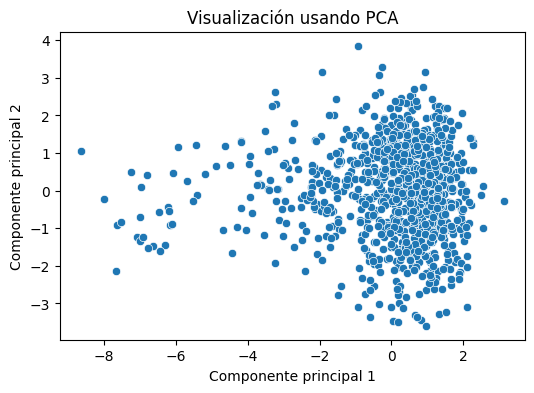

In [ ]:
plt.figure(figsize=(6,4))
sns.scatterplot(x=x_pca[:,0], y=x_pca[:,1])
plt.title('Visualización usando PCA')
plt.xlabel('Componente principal 1')
plt.ylabel('Componente principal 2')
plt.show()

In [ ]:
pca.explained_variance_ratio_ # solo 39% con dos componentes, ,usea IA para hacer un codo
                              # me recomendo 6 componentes para 70% pero los grupos de kmeans y de pca
                              # pero las graficas se complejisaron y la visualizacin igual
                              # y mantenian la misma forma, asi que decidi dejar solo 2

array([0.26637154, 0.13586686])

### la columna que mas peso tiene en el componente 1 es loudness, y en el 2 es danceability

# CLUSTERING

### Metodo del codo

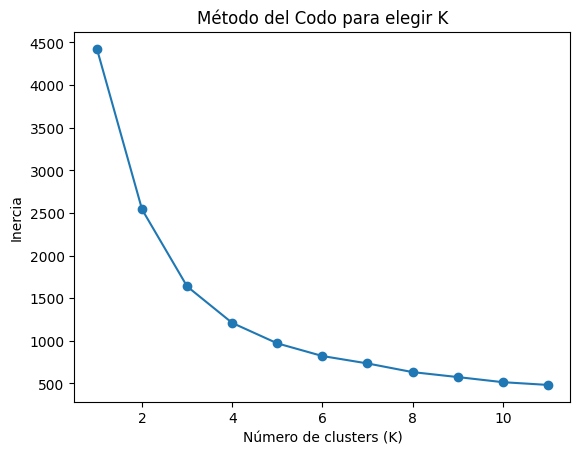

In [ ]:
inertias = []
k_range = range(1, 12)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42)
    km.fit(x_pca)
    inertias.append(km.inertia_)

plt.plot(k_range, inertias, marker='o')
plt.title('Método del Codo para elegir K')
plt.xlabel('Número de clusters (K)')
plt.ylabel('Inercia')
plt.show()

### Modelado K-Means

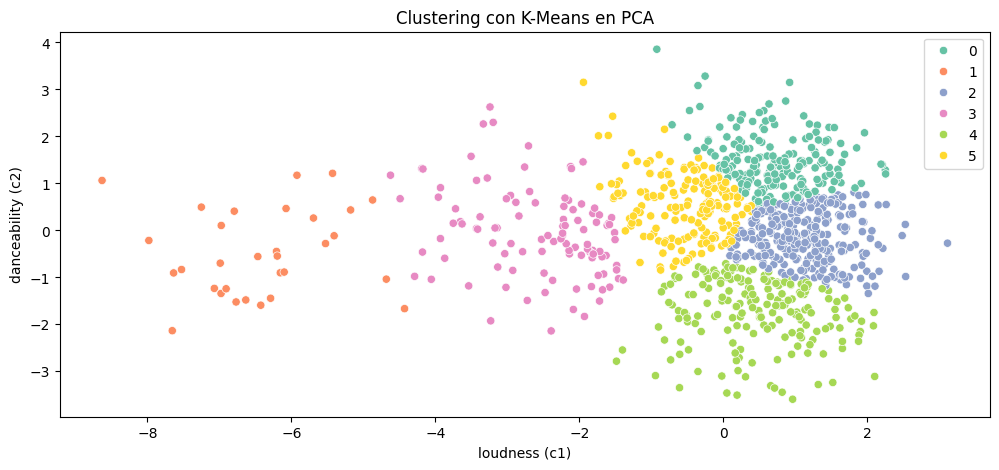

In [ ]:
kmeans = KMeans(n_clusters=6, random_state=42)
etiquetas = kmeans.fit(x_pca)
etiquetas.labels_

plt.figure(figsize=(12, 5))
sns.scatterplot(x=x_pca[:,0], y=x_pca[:,1], hue=etiquetas.labels_, palette = "Set2")
plt.title('Clustering con K-Means en PCA')
plt.xlabel('loudness (c1)')
plt.ylabel('danceability (c2)')
plt.show()

# ANALISIS DE CLUSTERS

In [ ]:
data_clusters = pd.concat([pd.DataFrame(df),pd.DataFrame(kmeans.labels_, columns=['Cluster'])], axis=1)
data_scaled_clusters = pd.concat([pd.DataFrame(data_scaled, columns=df.columns),pd.DataFrame(kmeans.labels_, columns=['Cluster'])], axis=1)

In [ ]:
data_clusters.head()

,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,Cluster
0,0.645,0.646,5,-8.334,1,0.0427,0.0615,0.000030,0.0740,0.295,115.842,5
1,0.795,0.630,7,-5.854,0,0.0434,0.1570,0.000000,0.0732,0.447,97.998,0
2,0.506,0.362,10,-9.480,1,0.0416,0.6700,0.000000,0.1760,0.385,84.726,3
3,0.650,0.825,0,-4.645,1,0.0325,0.0215,0.000024,0.0936,0.593,118.091,2
4,0.787,0.775,1,-6.614,1,0.0548,0.1900,0.000065,0.1130,0.787,118.998,0


In [ ]:
data_scaled_clusters.head()

,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,Cluster
0,0.200823,-0.070192,-0.067277,-0.262122,0.794557,-0.538762,-0.707668,-0.331336,-0.789715,-0.952150,-0.224734,5
1,1.098154,-0.147313,0.486445,0.291770,-1.258562,-0.531018,-0.376933,-0.331471,-0.795218,-0.299172,-0.861119,0
2,-0.630704,-1.439104,1.317029,-0.518074,0.794557,-0.550930,1.399684,-0.331471,-0.088114,-0.565518,-1.334449,3
3,0.230734,0.792609,-1.451583,0.561793,0.794557,-0.651599,-0.846195,-0.331363,-0.654898,0.328030,-0.144526,2
4,1.050296,0.551603,-1.174722,0.122029,0.794557,-0.404905,-0.262648,-0.331181,-0.521456,1.161436,-0.112179,0


In [ ]:
data_clusters.groupby('Cluster').agg(['mean', 'median'])

danceability            energy               key          loudness  \
                mean  median      mean  median      mean median       mean   
Cluster                                                                      
0           0.781423  0.7870  0.667368  0.6640  5.781095    6.0  -6.301194   
1           0.296871  0.2600  0.130295  0.1110  3.741935    3.0 -24.329710   
2           0.653912  0.6630  0.801095  0.8060  5.473684    6.0  -4.802993   
3           0.495292  0.4945  0.373680  0.3660  5.547170    6.0 -11.564028   
4           0.451995  0.4570  0.796609  0.8195  4.604167    4.0  -5.355083   
5           0.646011  0.6550  0.548708  0.5460  5.043243    5.0  -8.198897   

                      mode         ... acousticness          instrumentalness  \
          median      mean median  ...         mean   median             mean   
Cluster                            ...                                          
0        -5.8320  0.343284    0.0  ...     0.250265  0.21800         0.002805   
1       -25.1910  0.612903    1.0  ...     0.961258  0.98200         0.832065   
2        -4.7610  0.614035    1.0  ...     0.112828  0.05560         0.005235   
3       -11.2765  0.745283    1.0  ...     0.662230  0.72100         0.234861   
4        -5.1530  0.765625    1.0  ...     0.083657  0.02295         0.091928   
5        -7.7770  0.670270    1.0  ...     0.363908  0.33800         0.023269   

                   liveness           valence              tempo            
           median      mean  median      mean median        mean    median  
Cluster                                                                     
0        0.000000  0.136388  0.1090  0.721935  0.741  111.196776  109.9700  
1        0.898000  0.124548  0.1100  0.246497  0.120  115.478355  121.4560  
2        0.000000  0.224776  0.1610  0.574688  0.583  126.312832  125.9830  
3        0.001680  0.132848  0.1110  0.332751  0.310  117.410123  116.0795  
4        0.000018  0.268623  0.2165  0.370753  0.351  142.131318  143.3260  
5        0.000001  0.150358  0.1180  0.506208  0.502  110.698508  110.4270  

[6 rows x 22 columns]

<Axes: ylabel='Cluster'>

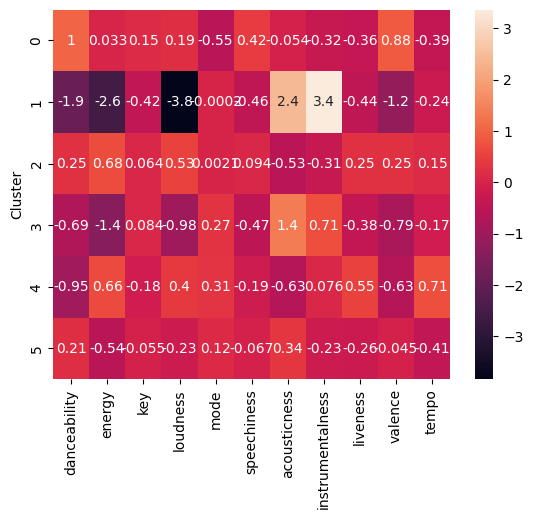

In [ ]:
sns.heatmap(data_scaled_clusters.groupby('Cluster').mean(), annot=True)

In [ ]:
pd.DataFrame(kmeans.labels_,columns=['Cluster'])['Cluster'].map({0: "muy baja", 1: "baja",2: "media", 3: "popular", 4: "muy popular", 5: "exito"})
#

,Cluster
0,exito
1,muy baja
2,popular
3,media
4,muy baja
...,...
995,media
996,media
997,media
998,media


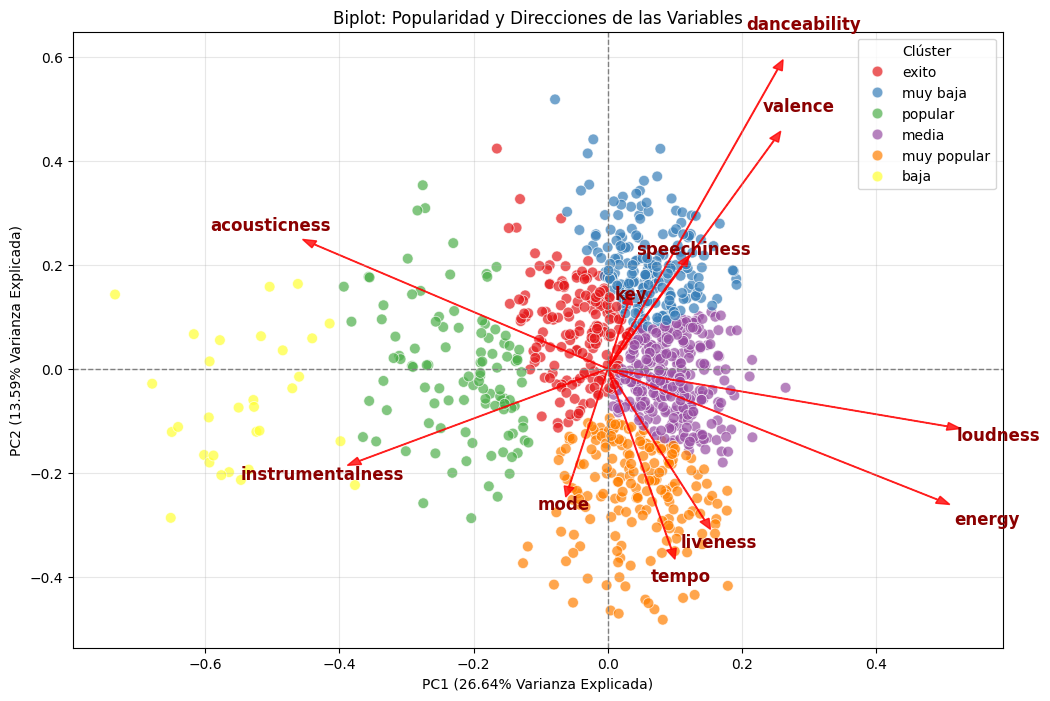

In [ ]:
# Función para generar el Biplot
def biplot(score, coeff, labels=None, target_clusters=None):
    plt.figure(figsize=(12, 8))
    # Coordenadas de los componentes principales (puntos de dispersión)
    xs = score[:, 0]
    ys = score[:, 1]
    n = coeff.shape[0] # Número de variables

    # Escalar los puntos para que convivan en el mismo espacio que los vectores (las flechas)
    scalex = 1.0 / (xs.max() - xs.min())
    scaley = 1.0 / (ys.max() - ys.min())

    # Graficar los jugadores, coloreados por su clúster de K-Means
    sns.scatterplot(x=xs * scalex, y=ys * scaley, hue=pd.DataFrame(target_clusters,columns=['Cluster'])['Cluster'].map({0: "muy baja", 1: "baja",2: "media", 3: "popular", 4: "muy popular", 5: "exito"}), palette='Set1', s=60, alpha=0.7)
    plt.legend(title='Clúster')

    # Graficar los vectores (cargas de las variables)
    for i in range(n):
        # Flecha del vector
        plt.arrow(0, 0, coeff[i, 0], coeff[i, 1], color='red', alpha=0.8,
                  head_width=0.015, head_length=0.02)
        # Etiqueta de la variable
        if labels is not None:
            plt.text(coeff[i, 0] * 1.15, coeff[i, 1] * 1.15, labels[i], color='darkred',
                     ha='center', va='center', fontsize=12, fontweight='bold')

    # Añadir los porcentajes de varianza explicada en los ejes
    var_pc1 = pca.explained_variance_ratio_[0] * 100
    var_pc2 = pca.explained_variance_ratio_[1] * 100

    plt.xlabel(f"PC1 ({var_pc1:.2f}% Varianza Explicada)")
    plt.ylabel(f"PC2 ({var_pc2:.2f}% Varianza Explicada)")
    plt.title("Biplot: Popularidad y Direcciones de las Variables")

    # Dibujar líneas en el origen (0,0) para guiar la vista
    plt.axhline(0, color='gray', linestyle='--', linewidth=1)
    plt.axvline(0, color='gray', linestyle='--', linewidth=1)
    plt.grid(alpha=0.3)
    plt.show()

# Ejecutar el gráfico
# Pasamos la matriz transpuesta de pca.components_ para que cada fila sea un vector x,y
biplot(x_pca, np.transpose(pca.components_), labels=df.columns, target_clusters=kmeans.labels_)

,canciones,popularidad_media,popularidad_mediana
Cluster,,,
2,283,64.84,69.0
0,201,63.59,70.0
5,185,59.28,69.0
4,192,54.92,64.0
1,31,49.32,56.0
3,106,48.52,63.0


Cluster identificado como de mayor popularidad: 2


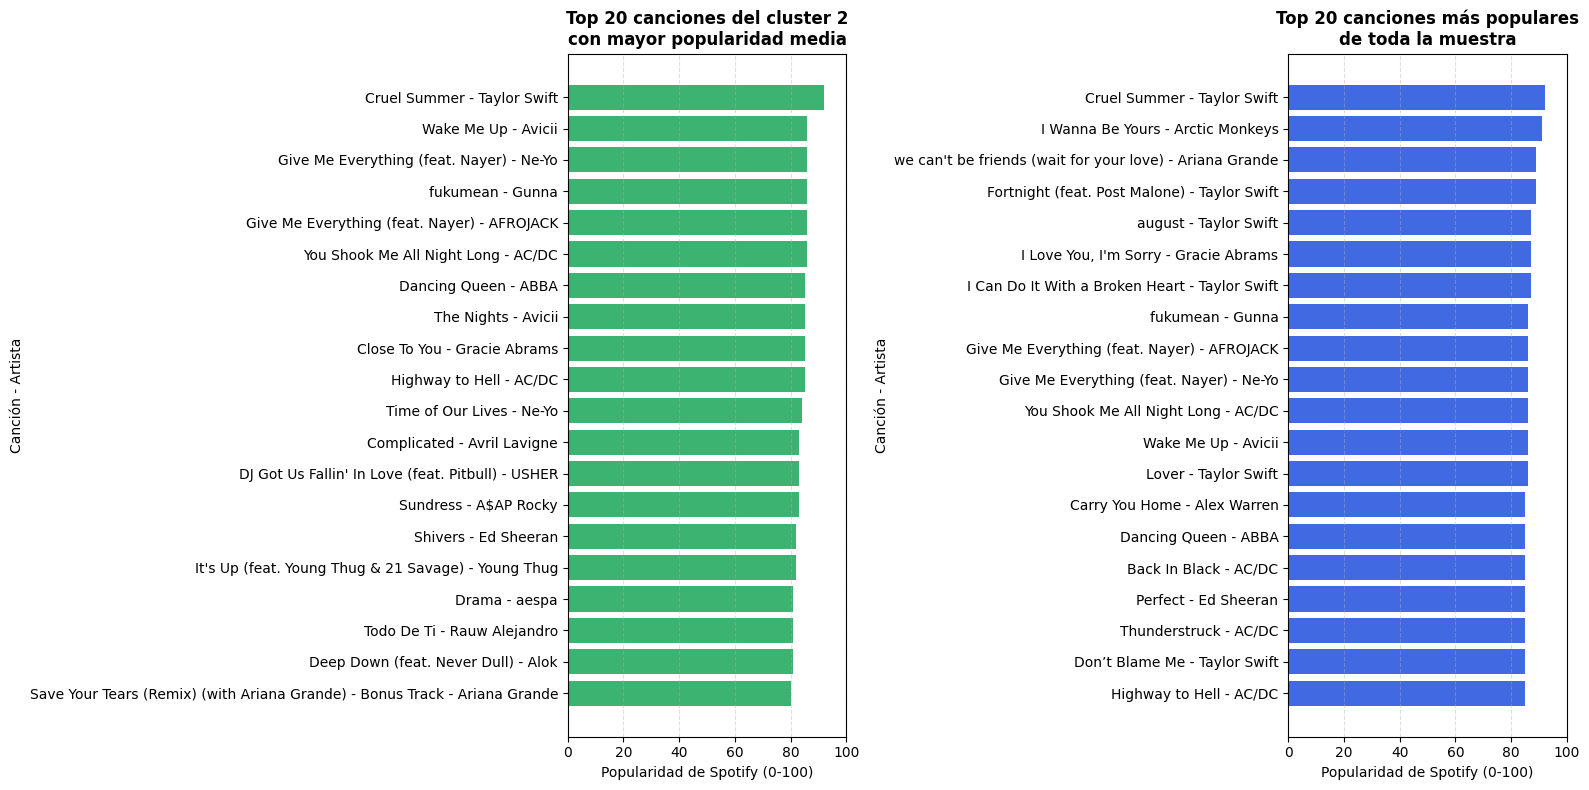

In [ ]:
# ============================================
# COMPARACIÓN: ÉXITOS DEL CLUSTER VS TOP 20 GLOBAL (LADO A LADO)
# ============================================

# 1. Asociar cada canción con su cluster de K-Means
tabla_resultados = tabla.copy()
tabla_resultados['Cluster'] = kmeans.labels_

# Asegurar que la popularidad sea numérica
tabla_resultados['track_popularity'] = pd.to_numeric(tabla_resultados['track_popularity'],errors='coerce')

# Evitar canciones duplicadas por nombre y artista
tabla_resultados = tabla_resultados.drop_duplicates(subset=['track_name', 'artist_name']).copy()

# Crear etiqueta para mostrar canción y artista
tabla_resultados['track_artist'] = (tabla_resultados['track_name'].fillna('Sin título').astype(str) + ' - ' + tabla_resultados['artist_name'].fillna('Artista desconocido').astype(str))

# 2. Comparar la popularidad promedio de los clusters
resumen_clusters = tabla_resultados.groupby('Cluster').agg(canciones=('track_popularity', 'count'),popularidad_media=('track_popularity', 'mean'),popularidad_mediana=('track_popularity', 'median')).round(2)

display(resumen_clusters.sort_values('popularidad_media', ascending=False))

# Identificar el cluster con mayor popularidad promedio
cluster_exito = resumen_clusters['popularidad_media'].idxmax()

print(f"Cluster identificado como de mayor popularidad: {cluster_exito}")

# 3. TOP 20 canciones del cluster de mayor popularidad
top_20_exitos_cluster = (tabla_resultados[(tabla_resultados['Cluster'] == cluster_exito) & (tabla_resultados['track_popularity'].notna())].sort_values('track_popularity', ascending=False).head(20).sort_values('track_popularity', ascending=True))

# 4. TOP 20 canciones más populares de toda la muestra
top_20_global = (tabla_resultados[tabla_resultados['track_popularity'].notna()].sort_values('track_popularity', ascending=False).head(20).sort_values('track_popularity', ascending=True))

# 5. Crear la figura con subplots lado a lado (1 fila, 2 columnas)
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Gráfico Izquierdo: Éxitos del cluster
axes[0].barh(top_20_exitos_cluster['track_artist'],top_20_exitos_cluster['track_popularity'],color='mediumseagreen')
axes[0].set_title(f'Top 20 canciones del cluster {cluster_exito}\ncon mayor popularidad media',fontsize=12,fontweight='bold')
axes[0].set_xlabel('Popularidad de Spotify (0-100)', fontsize=10)
axes[0].set_ylabel('Canción - Artista', fontsize=10)
axes[0].set_xlim(0, 100)
axes[0].grid(axis='x', linestyle='--', alpha=0.4)

# Gráfico Derecho: Éxitos globales de toda la muestra
axes[1].barh(top_20_global['track_artist'],top_20_global['track_popularity'],color='royalblue')
axes[1].set_title('Top 20 canciones más populares\nde toda la muestra',fontsize=12,fontweight='bold')
axes[1].set_xlabel('Popularidad de Spotify (0-100)', fontsize=10)
axes[1].set_ylabel('Canción - Artista', fontsize=10)
axes[1].set_xlim(0, 100)
axes[1].grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

# Conclusiones

In [ ]:
# 1. Extraer los nombres únicos de las canciones de ambos conjuntos
canciones_cluster = set(top_20_exitos_cluster['track_artist'])
canciones_global = set(top_20_global['track_artist'])

# 2. Encontrar la intersección de ambos conjuntos
canciones_repetidas = list(canciones_cluster.intersection(canciones_global))

# 3. Mostrar los resultados
print(f"Número de canciones que aparecen en ambas listas: {len(canciones_repetidas)}")
print("\nLista de canciones repetidas:")
for idx, cancion in enumerate(sorted(canciones_repetidas), 1):
    print(f"{idx}. {cancion}")

Número de canciones que aparecen en ambas listas: 8

Lista de canciones repetidas:
1. Cruel Summer - Taylor Swift
2. Dancing Queen - ABBA
3. Give Me Everything (feat. Nayer) - AFROJACK
4. Give Me Everything (feat. Nayer) - Ne-Yo
5. Highway to Hell - AC/DC
6. Wake Me Up - Avicii
7. You Shook Me All Night Long - AC/DC
8. fukumean - Gunna


Las canciones que se repiten en ambas listas, nos indica que tanto por clustering como por indice de popularidad tenemos 8 canciones que son las mas populares:

1. Cruel Summer - Taylor Swift
2. Dancing Queen - ABBA
3. Give Me Everything (feat. Nayer) - AFROJACK
4. Give Me Everything (feat. Nayer) - Ne-Yo
5. Highway to Hell - AC/DC
6. Wake Me Up - Avicii
7. You Shook Me All Night Long - AC/DC
8. fukumean - Gunna

In [ ]:
# 1. Combinar los artistas de ambas listas (Top 20 del clúster más popular y Top 20 global)
artistas_combinados = pd.concat([
    top_20_exitos_cluster['artist_name'],
    top_20_global['artist_name']
])

# 2. Contar la frecuencia de aparición de cada artista
conteo_artistas = artistas_combinados.value_counts()

print(conteo_artistas[conteo_artistas > 1].to_string())

artist_name
Taylor Swift     7
AC/DC            6
Avicii           3
Ne-Yo            3
Gunna            2
Ariana Grande    2
ABBA             2
Gracie Abrams    2
AFROJACK         2
Ed Sheeran       2


Los artistas que más se repiten en ambas listas, nos indica que tanto por clustering como por indice de popularidad de sus canción, tenemos 4 artistas pricipales:

1. Taylor Swift     7
2. AC/DC            6
3. Avicii           3
3. Ne-Yo            3

In [ ]:
# 1. Obtener la lista única de artistas combinados de ambas selecciones
artistas_unicos = pd.concat([
    top_20_exitos_cluster['artist_name'],
    top_20_global['artist_name']
]).unique()

# 2. Filtrar el dataframe original para obtener la información de géneros de estos artistas
# Evitamos duplicados por artista para contar géneros representativos de cada artista
artistas_generos = tabla[tabla['artist_name'].isin(artistas_unicos)].drop_duplicates(subset=['artist_name'])

# 3. Limpiar y separar los géneros (ya que pueden venir en listas o cadenas separadas por comas)
generos_lista = []
for g in artistas_generos['genres'].dropna():
    # Si los géneros están separados por comas, los dividimos y limpiamos espacios
    generos_lista.extend([gen.strip().lower() for gen in str(g).split(',') if gen.strip()])

# 4. Contar las frecuencias de los géneros y tomar los 3 más comunes
top_3_generos = pd.Series(generos_lista).value_counts().head(3)

for idx, (genero, count) in enumerate(top_3_generos.items(), 1):
    print(f"{idx}. {genero.capitalize()} ({count} artistas)")

1. Pop (7 artistas)
2. Dance pop (5 artistas)
3. Rap (4 artistas)


Los 3 géneros que más se repiten entre los artistas de ambas listas combinadas:

1. Pop (7 artistas)
2. Dance pop (5 artistas)
3. Rap (4 artistas)